# Bagian 1 – Persiapan Dataset (Azmi)
**Tugas JST: Klasifikasi Jenis Sampah dengan CNN (VGG16 Transfer Learning)**

Notebook ini menyiapkan data untuk tahap training (Acang):
1. Mengunduh dataset TrashNet (6 kelas, 2.527 gambar)
2. Melihat jumlah gambar per kelas dan contoh gambarnya
3. Membagi data menjadi train / validation / test (70 / 15 / 15)
4. Menyiapkan preprocessing (resize 224×224, normalisasi VGG16) dan augmentasi
5. Menghitung *class weight* karena kelas `trash` jauh lebih sedikit
6. Menyimpan hasil ke Google Drive supaya bisa langsung dipakai Acang

Semua grafik disimpan ke folder `figures/` untuk dipakai di slide 5 dan 6.

> Jalankan di Google Colab: **Runtime → Run all**. GPU belum diperlukan di tahap ini.

In [ ]:
import os, shutil, random, zipfile, urllib.request
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = (224, 224)   # ukuran input VGG16
BATCH_SIZE = 32
os.makedirs("figures", exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Unduh dataset
Sumber: **TrashNet** (Thung & Yang, 2016), repositori GitHub `garythung/trashnet`. Dataset yang sama juga ada di Kaggle dengan nama *Garbage Classification*.

In [ ]:
URL = "https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip"
ZIP_PATH = "dataset-resized.zip"
if not os.path.exists(ZIP_PATH):
    print("Mengunduh dataset ...")
    urllib.request.urlretrieve(URL, ZIP_PATH)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("raw")

# cari folder yang berisi 6 subfolder kelas (abaikan __MACOSX)
RAW_DIR = None
for root, dirs, files in os.walk("raw"):
    if "__MACOSX" in root:
        continue
    if {"cardboard", "glass", "metal", "paper", "plastic", "trash"}.issubset(set(dirs)):
        RAW_DIR = root; break
print("Folder dataset:", RAW_DIR)

CLASSES = sorted(d for d in os.listdir(RAW_DIR) if os.path.isdir(os.path.join(RAW_DIR, d)))
print("Kelas:", CLASSES)

Mengunduh dataset ...
Folder dataset: raw/dataset-resized
Kelas: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


*Kalau unduhan dari GitHub gagal*, pakai Kaggle: unduh **Garbage Classification** dari kaggle.com, upload zip-nya ke Colab, lalu ganti `ZIP_PATH` dengan nama file tersebut dan jalankan ulang sel di atas.

## 2. Jumlah gambar per kelas

cardboard  (Kardus ):  403  (15.9%)
glass      (Kaca   ):  501  (19.8%)
metal      (Logam  ):  410  (16.2%)
paper      (Kertas ):  594  (23.5%)
plastic    (Plastik):  482  (19.1%)
trash      (Residu ):  137  (5.4%)
Total: 2527


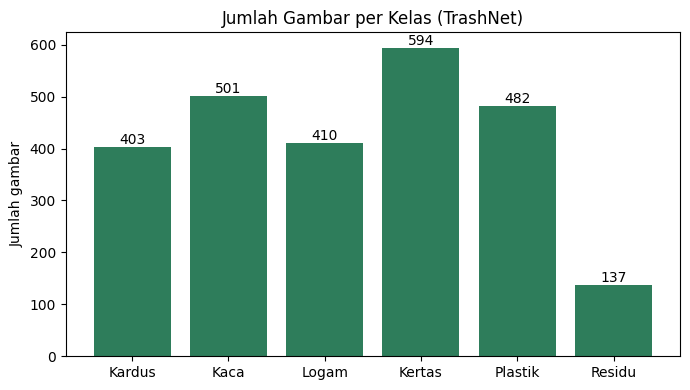

In [ ]:
LABEL_ID = {"cardboard": "Kardus", "glass": "Kaca", "metal": "Logam",
            "paper": "Kertas", "plastic": "Plastik", "trash": "Residu"}
counts = {c: len([f for f in os.listdir(os.path.join(RAW_DIR, c)) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
          for c in CLASSES}
total = sum(counts.values())
for c, n in counts.items():
    print(f"{c:10s} ({LABEL_ID[c]:7s}): {n:4d}  ({n/total:.1%})")
print("Total:", total)

plt.figure(figsize=(7, 4))
bars = plt.bar([LABEL_ID[c] for c in CLASSES], [counts[c] for c in CLASSES], color="#2E7D5B")
plt.bar_label(bars)
plt.title("Jumlah Gambar per Kelas (TrashNet)")
plt.ylabel("Jumlah gambar")
plt.tight_layout(); plt.savefig("figures/distribusi_kelas.png", dpi=200); plt.show()

## 3. Contoh gambar tiap kelas

Ukuran asli gambar: (512, 384)


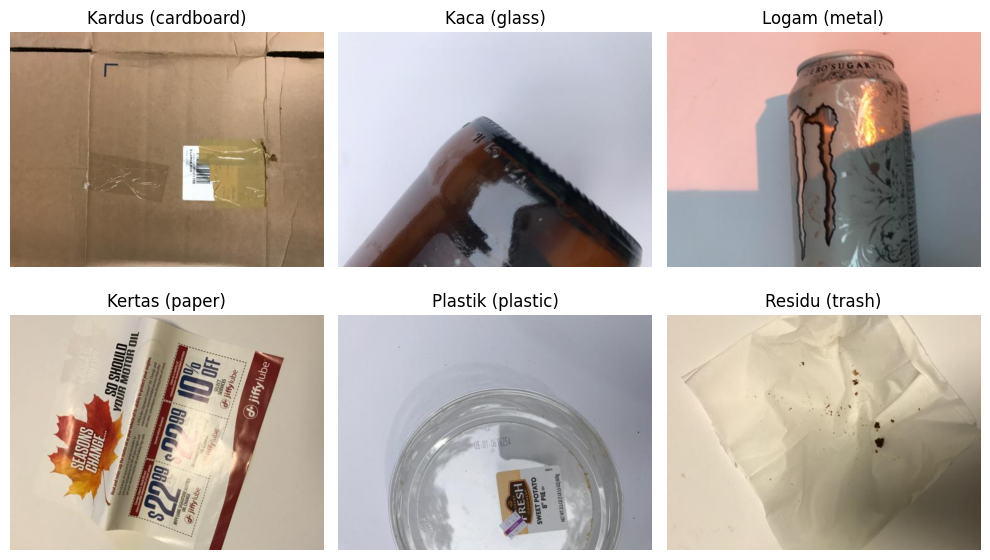

In [ ]:
from PIL import Image
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, c in zip(axes.ravel(), CLASSES):
    f = random.choice(os.listdir(os.path.join(RAW_DIR, c)))
    img = Image.open(os.path.join(RAW_DIR, c, f))
    ax.imshow(img); ax.set_title(f"{LABEL_ID[c]} ({c})"); ax.axis("off")
print("Ukuran asli gambar:", img.size)
plt.tight_layout(); plt.savefig("figures/contoh_gambar.png", dpi=200); plt.show()

## 4. Split data: train 70% / validation 15% / test 15%
Pembagian **stratified**, jadi proporsi tiap kelas sama di ketiga bagian. Hasilnya disalin ke folder `data_split/train|val|test/<kelas>`.

In [ ]:
paths, labels = [], []
for c in CLASSES:
    for f in os.listdir(os.path.join(RAW_DIR, c)):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(RAW_DIR, c, f)); labels.append(c)

p_train, p_tmp, y_train, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

SPLIT_DIR = "data_split"
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)
for name, ps, ys in [("train", p_train, y_train), ("val", p_val, y_val), ("test", p_test, y_test)]:
    for p, y in zip(ps, ys):
        dst = os.path.join(SPLIT_DIR, name, y); os.makedirs(dst, exist_ok=True)
        shutil.copy(p, dst)
    cnt = Counter(ys)
    print(f"{name:5s}: {len(ps):4d} gambar ->", {c: cnt[c] for c in CLASSES})

train: 1768 gambar -> {'cardboard': 282, 'glass': 350, 'metal': 287, 'paper': 416, 'plastic': 337, 'trash': 96}
val  :  379 gambar -> {'cardboard': 61, 'glass': 75, 'metal': 61, 'paper': 89, 'plastic': 72, 'trash': 21}
test :  380 gambar -> {'cardboard': 60, 'glass': 76, 'metal': 62, 'paper': 89, 'plastic': 73, 'trash': 20}


## 5. Preprocessing
- Resize ke **224×224** piksel (ukuran input VGG16)
- Normalisasi dengan `tf.keras.applications.vgg16.preprocess_input` (RGB → BGR dan pengurangan rata-rata piksel ImageNet), sama seperti saat VGG16 dilatih

In [ ]:
def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(SPLIT_DIR, split), labels="inferred", label_mode="categorical",
        class_names=CLASSES, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED)

train_raw = load("train", True)
val_raw   = load("val", False)
test_raw  = load("test", False)
preprocess = tf.keras.applications.vgg16.preprocess_input

Found 1768 files belonging to 6 classes.
Found 379 files belonging to 6 classes.
Found 380 files belonging to 6 classes.


## 6. Augmentasi data (hanya untuk data train)
Augmentasi membuat variasi gambar baru setiap epoch supaya model tidak *overfitting*:
flip horizontal, rotasi ±18°, zoom ±10%, geser posisi ±10%, perubahan kecerahan ±10%.

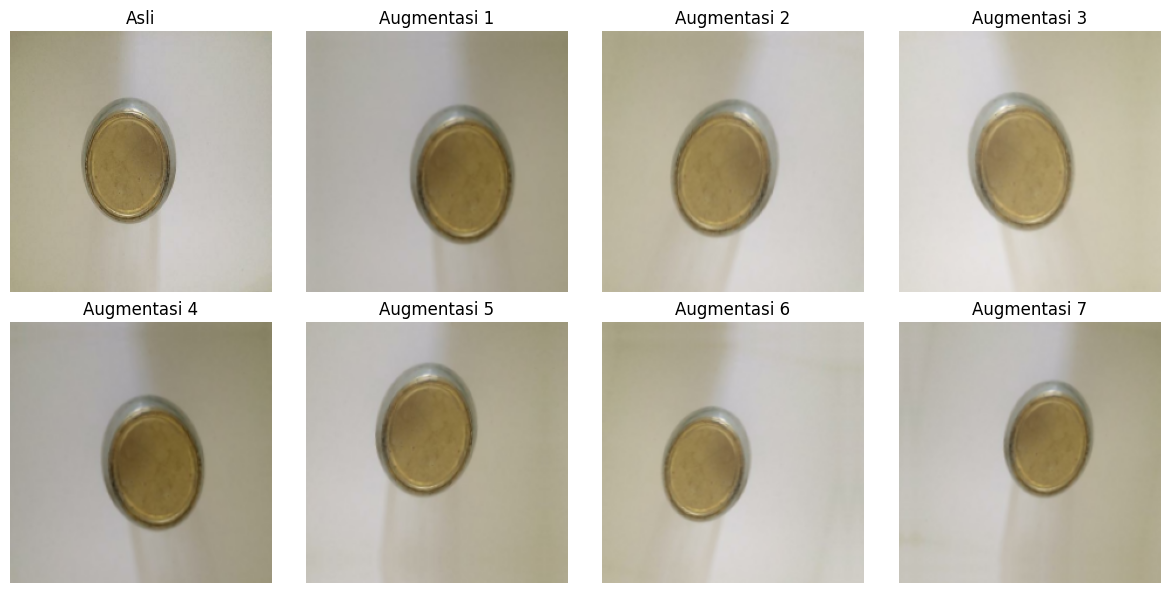

In [ ]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),        # 0.05 x 360 derajat = ±18 derajat
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="augmentasi")

# Pratinjau augmentasi: 1 gambar asli + 7 variasi
imgs, _ = next(iter(train_raw))
sample = imgs[0]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.ravel()
axes[0].imshow(sample.numpy().astype("uint8")); axes[0].set_title("Asli"); axes[0].axis("off")
for i in range(1, 8):
    aug = augment(tf.expand_dims(sample, 0), training=True)[0]
    axes[i].imshow(np.clip(aug.numpy(), 0, 255).astype("uint8")); axes[i].set_title(f"Augmentasi {i}"); axes[i].axis("off")
plt.tight_layout(); plt.savefig("figures/contoh_augmentasi.png", dpi=200); plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = (train_raw.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
                     .map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE))
val_ds  = val_raw.map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_raw.map(lambda x, y: (preprocess(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

xb, yb = next(iter(train_ds))
print("Bentuk batch:", xb.shape, yb.shape)   # (32, 224, 224, 3) (32, 6)

Bentuk batch: (32, 224, 224, 3) (32, 6)


## 7. Class weight
Kelas `trash` (residu) hanya ±5% dari data. *Class weight* memberi bobot lebih besar pada kelas yang sedikit saat training, supaya model tidak mengabaikannya.

In [ ]:
cw = compute_class_weight("balanced", classes=np.array(CLASSES), y=np.array(y_train))
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(cw)}
for i, c in enumerate(CLASSES):
    print(f"{c:10s}: {CLASS_WEIGHT[i]:.2f}")

cardboard : 1.04
glass     : 0.84
metal     : 1.03
paper     : 0.71
plastic   : 0.87
trash     : 3.07


## 8. Simpan untuk Acang (Google Drive)
Hasil split dan gambar untuk slide disimpan ke `MyDrive/Tugas_JST/`. Bagikan folder itu ke Acang dan Raniyol.

Untuk tahap training, Acang cukup menjalankan ulang **sel bagian 5–7** dengan `SPLIT_DIR` diarahkan ke folder Drive, lalu memakai `train_ds`, `val_ds`, `test_ds`, dan `CLASS_WEIGHT`.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
OUT = "/content/drive/MyDrive/Tugas_JST"
os.makedirs(OUT, exist_ok=True)
shutil.make_archive(os.path.join(OUT, "data_split"), "zip", SPLIT_DIR)
shutil.copytree("figures", os.path.join(OUT, "figures"), dirs_exist_ok=True)
print("Tersimpan di", OUT)
print(os.listdir(OUT))

Mounted at /content/drive
Tersimpan di /content/drive/MyDrive/Tugas_JST
['data_split.zip', 'figures']
